# SMILES Molecular Structure and Atom Number Viewer

Enter a SMILES string below to view the molecule's 2D structure with 0-based atom numbering. These numbers can be used when filling in the sub_id  column of cores.xls or substituents.xlsxx.

Requires the rdkit package

In [1]:
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True

def draw_molecules(molecule_list):
    img = Draw.MolsToGridImage(molecule_list, molsPerRow=5, subImgSize=(300, 300))
    return img
    
def mol_with_atom_index(mol):
    atoms = mol.GetNumAtoms()
    for idx in range(atoms):
        mol.GetAtomWithIdx(idx).SetProp('molAtomMapNumber', str(mol.GetAtomWithIdx(idx).GetIdx()))
    return mol

def draw_indexmolecules(mol_list):
    mols_with_index = [mol_with_atom_index(mol) for mol in mol_list]  # 为每个分子添加原子编号
    img = Draw.MolsToGridImage(mols_with_index, molsPerRow=2, subImgSize=(300, 300))
    return img

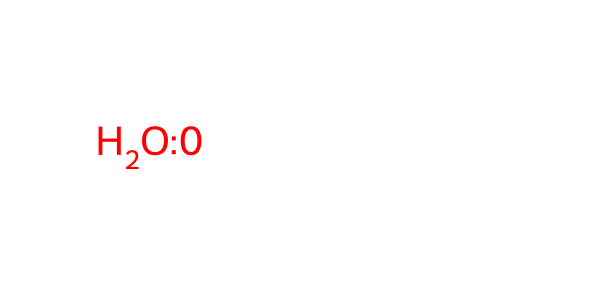

In [2]:
smi_list = ['[H]O[H]'] # input your SMILES
mol = [Chem.MolFromSmiles(smi) for smi in smi_list]
draw_indexmolecules(mol)